# Lab 4: Dynamic Programming, Monte Carlo and TD(0) on GridWorld

**Course:** Reinforcement Learning, Semester 6, Plaksha University

1. **Policy evaluation (DP)** of the equiprobable random policy on an N x N GridWorld, the effect of gamma, theta and grid size on convergence, and deterministic vs stochastic (slippery) moves.
2. **Monte Carlo prediction:** first-visit vs every-visit on a small 2 x 3 grid, and MC estimates from given episodes.
3. **Monte Carlo control** on a given trajectory.
4. **Batch TD(0)** on the A-B example.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(26)

## GridWorld environment

In [2]:
class GridWorld:
    """
    Generalized M×N GridWorld environment.

    State space : S = {0, 1, ..., nrows*ncols - 1}
        Row-major indexing: state s  →  row = s // ncols,  col = s % ncols

    Actions     : 0=up, 1=down, 2=left, 3=right
    Dynamics    : deterministic (default) or stochastic.
                  Stochastic: P(intended) = 1 - 2*slip_prob,
                              P(each perpendicular direction) = slip_prob
    Reward      : -1 on every non-terminal transition (default),
                  or provided via reward_fn(state, action, next_state) -> float
    Policy      : initialised to the equiprobable random policy (0.25 each action)

    Parameters
    ----------
    N                : number of rows (grid side length when square)
    terminal_states  : set of in-grid terminal state indices, e.g. {0, N*N-1}
    ncols            : number of columns; defaults to N (square grid)
    stochastic       : if True, actions have stochastic outcomes
    slip_prob        : probability of slipping to each perpendicular direction
                       (used when stochastic=True; default 0.1 gives 0.8/0.1/0.1)
    reward_fn        : callable (state, action, next_state) -> float;
                       overrides the default -1 reward when provided
    boundary_terminal: dict {action_idx: reward} — when the agent tries to move
                       out of bounds in a listed direction, the episode ends with
                       the given reward instead of bouncing back.
                       Example for Q2.1: {0: +1.0, 1: -1.0}
    """

    ACTIONS = {0: "up", 1: "down", 2: "left", 3: "right"}
    _DELTAS  = {0: (-1, 0), 1: (1, 0), 2: (0, -1), 3: (0, 1)}   # (Δrow, Δcol)
    # Perpendicular (orthogonal) action pairs used for stochastic slip
    _PERP    = {0: (2, 3), 1: (2, 3), 2: (0, 1), 3: (0, 1)}

    def __init__(
        self,
        N: int,
        terminal_states: set,
        ncols: int = None,
        stochastic: bool = False,
        slip_prob: float = 0.1,
        reward_fn=None,
        boundary_terminal: dict = None,
    ):
        if N < 1:
            raise ValueError("Grid rows N must be at least 1.")
        _ncols = ncols if ncols is not None else N
        if _ncols < 1:
            raise ValueError("Grid cols ncols must be at least 1.")

        self.N     = N          # number of rows (kept for backward compatibility)
        self.nrows = N
        self.ncols = _ncols
        self.n_states  = self.nrows * self.ncols
        self.n_actions = len(self.ACTIONS)

        # Virtual absorbing state reached when boundary_terminal is triggered.
        # Its index (n_states) lies outside the normal state range so that
        # algorithms iterating over range(n_states) never process it, yet
        # is_terminal() returns True for it.
        self._boundary_state = self.n_states

        invalid = {s for s in terminal_states if not (0 <= s < self.n_states)}
        if invalid:
            raise ValueError(
                f"Terminal states out of range [0, {self.n_states - 1}]: {invalid}"
            )
        self.terminal_states = frozenset(terminal_states)

        self.stochastic        = stochastic
        self.slip_prob         = float(slip_prob)
        self.reward_fn         = reward_fn
        self.boundary_terminal = dict(boundary_terminal) if boundary_terminal else {}

        # Equiprobable random policy: π(a|s) = 1/n_actions for all s, a
        # Shape: (n_states, n_actions)
        self.policy = np.ones((self.n_states, self.n_actions)) / self.n_actions

    # ------------------------------------------------------------------
    # Internal helpers
    # ------------------------------------------------------------------

    def _move(self, state: int, action: int):
        """
        Attempt one grid step from *state* in *action* direction.

        Returns
        -------
        next_state : int   — new state index, or _boundary_state if OOB-terminal
        reward     : float
        done       : bool
        """
        row, col = divmod(state, self.ncols)
        dr, dc   = self._DELTAS[action]
        new_row, new_col = row + dr, col + dc

        if 0 <= new_row < self.nrows and 0 <= new_col < self.ncols:
            # Valid move inside the grid
            next_state = new_row * self.ncols + new_col
            done   = next_state in self.terminal_states
            reward = self._get_reward(state, action, next_state)
            return next_state, reward, done

        # Out of bounds
        if action in self.boundary_terminal:
            # Transition to the virtual absorbing terminal state
            return self._boundary_state, float(self.boundary_terminal[action]), True

        # Bounce — stay in place, still alive
        reward = self._get_reward(state, action, state)
        return state, reward, False

    def _get_reward(self, state: int, action: int, next_state: int) -> float:
        """Dispatch to custom reward_fn or return the default -1."""
        if self.reward_fn is not None:
            return float(self.reward_fn(state, action, next_state))
        return -1.0

    # ------------------------------------------------------------------
    # Core dynamics
    # ------------------------------------------------------------------

    def get_transitions(self, state: int, action: int):
        """
        Return the transition distribution as a list of
        ``(probability, next_state, reward, done)`` tuples.

        Works for both deterministic and stochastic dynamics and is
        compatible with standard DP interfaces.
        """
        if self.is_terminal(state):
            return [(1.0, state, 0.0, True)]

        if not self.stochastic:
            ns, r, d = self._move(state, action)
            return [(1.0, ns, r, d)]

        # Stochastic: aggregate probabilities over intended + perpendicular actions
        intended_prob = 1.0 - 2.0 * self.slip_prob
        candidates = [
            (action,                intended_prob),
            (self._PERP[action][0], self.slip_prob),
            (self._PERP[action][1], self.slip_prob),
        ]
        agg: dict = {}
        for act, prob in candidates:
            ns, r, d = self._move(state, act)
            key = (ns, r, d)
            agg[key] = agg.get(key, 0.0) + prob

        return [(prob, ns, r, d) for (ns, r, d), prob in agg.items()]

    def step(self, state: int, action: int):
        """
        Sample one transition from *state* under *action*.

        Returns
        -------
        next_state : int
        reward     : float  (0 if already terminal)
        done       : bool
        """
        if self.is_terminal(state):
            return state, 0.0, True

        transitions = self.get_transitions(state, action)
        if len(transitions) == 1:
            _, ns, r, d = transitions[0]
            return ns, r, d

        probs = [t[0] for t in transitions]
        idx   = np.random.choice(len(transitions), p=probs)
        _, ns, r, d = transitions[idx]
        return ns, r, d

    # ------------------------------------------------------------------
    # Episode generation
    # ------------------------------------------------------------------

    def generate_episode(self, start_state: int = None, max_steps: int = 1000):
        """
        Roll out one episode following the current policy.

        Parameters
        ----------
        start_state : starting state index; if None, sampled uniformly from
                      all non-terminal in-grid states
        max_steps   : safety cap on episode length

        Returns
        -------
        episode : list of (state, action, reward) tuples
        """
        if start_state is None:
            non_terminal = [
                s for s in range(self.n_states) if not self.is_terminal(s)
            ]
            if not non_terminal:
                raise ValueError("All states are terminal; cannot start an episode.")
            start_state = int(np.random.choice(non_terminal))

        episode = []
        state   = start_state

        for _ in range(max_steps):
            if self.is_terminal(state):
                break
            action               = self.sample_action(state)
            next_state, reward, done = self.step(state, action)
            episode.append((state, action, reward))
            state = next_state
            if done:
                break

        return episode

    # ------------------------------------------------------------------
    # Policy helpers
    # ------------------------------------------------------------------

    def sample_action(self, state: int) -> int:
        """Sample an action from the current policy at *state*."""
        return int(np.random.choice(self.n_actions, p=self.policy[state]))

    def set_policy(self, policy: np.ndarray):
        """
        Replace the policy table.

        Parameters
        ----------
        policy : array of shape (n_states, n_actions) with rows summing to 1
        """
        policy = np.asarray(policy, dtype=float)
        if policy.shape != (self.n_states, self.n_actions):
            raise ValueError(
                f"Policy shape must be ({self.n_states}, {self.n_actions}), "
                f"got {policy.shape}."
            )
        if not np.allclose(policy.sum(axis=1), 1.0):
            raise ValueError("Each row of policy must sum to 1.")
        self.policy = policy

    def update_policy_greedy(self, Q: np.ndarray):
        """
        Set policy to be greedy with respect to *Q*.

        Parameters
        ----------
        Q : array of shape (n_states, n_actions)
        """
        for s in range(self.n_states):
            if not self.is_terminal(s):
                best_a = int(np.argmax(Q[s]))
                self.policy[s]        = 0.0
                self.policy[s][best_a] = 1.0

    def update_policy_epsilon_greedy(self, Q: np.ndarray, epsilon: float):
        """
        Set policy to ε-greedy with respect to *Q*.

        Parameters
        ----------
        Q       : array of shape (n_states, n_actions)
        epsilon : exploration probability ε ∈ [0, 1]
        """
        for s in range(self.n_states):
            if not self.is_terminal(s):
                best_a = int(np.argmax(Q[s]))
                self.policy[s]        = epsilon / self.n_actions
                self.policy[s][best_a] += 1.0 - epsilon

    # ------------------------------------------------------------------
    # Coordinate helpers
    # ------------------------------------------------------------------

    def state_to_coords(self, state: int):
        """Convert a state index to (row, col)."""
        return divmod(state, self.ncols)

    def coords_to_state(self, row: int, col: int) -> int:
        """Convert (row, col) to a state index."""
        return row * self.ncols + col

    def is_terminal(self, state: int) -> bool:
        """True for in-grid terminal states and the virtual boundary-terminal state."""
        return state in self.terminal_states or state == self._boundary_state

    # ------------------------------------------------------------------
    # Rendering
    # ------------------------------------------------------------------

    def render(self, highlight_state: int = None):
        """Print an ASCII grid. 'T' = terminal, 'A' = agent, '.' = empty."""
        border = "+" + "---+" * self.ncols
        print(border)
        for row in range(self.nrows):
            row_cells = []
            for col in range(self.ncols):
                s = self.coords_to_state(row, col)
                if s == highlight_state:
                    row_cells.append(" A ")
                elif s in self.terminal_states:
                    row_cells.append(" T ")
                else:
                    row_cells.append(" . ")
            print("|" + "|".join(row_cells) + "|")
            print(border)

    def render_values(self, V, fmt: str = ".2f"):
        """
        Print the value function as an nrows × ncols grid.

        Parameters
        ----------
        V   : array-like of length n_states
        fmt : format specifier for float values (default '.2f')
        """
        V = np.asarray(V)
        for row in range(self.nrows):
            row_strs = []
            for col in range(self.ncols):
                s   = self.coords_to_state(row, col)
                val = float(V[s]) if s < len(V) else 0.0
                row_strs.append(f"{val:{fmt}}")
            print("  ".join(row_strs))

    def __repr__(self):
        shape = f"{self.nrows}×{self.ncols}"
        return (
            f"GridWorld({shape}, n_states={self.n_states}, "
            f"terminal_states={set(self.terminal_states)}, "
            f"stochastic={self.stochastic})"
        )


## Part 1: Iterative policy evaluation

In [3]:
def policy_eval(env, gamma=1.0, theta=1e-4):
    V = np.zeros(env.n_states)
    deltas = []

    while True:
        delta = 0
        new_V = V.copy()

        for s in range(env.n_states):
            if env.is_terminal(s):
                continue

            v = 0
            for a, pi in enumerate(env.policy[s]):
                transitions = env.get_transitions(s, a)
                for p, ns, r, _ in transitions:
                    v += pi * p * (r + gamma * V[ns if ns < env.n_states else 0])

            new_V[s] = v
            delta = max(delta, abs(V[s] - v))

        V = new_V
        deltas.append(delta)

        if delta < theta:
            break

    return V, deltas


Iterations to converge: 173
0.00  -14.00  -20.00  -22.00
-14.00  -18.00  -20.00  -20.00
-20.00  -20.00  -18.00  -14.00
-22.00  -20.00  -14.00  0.00


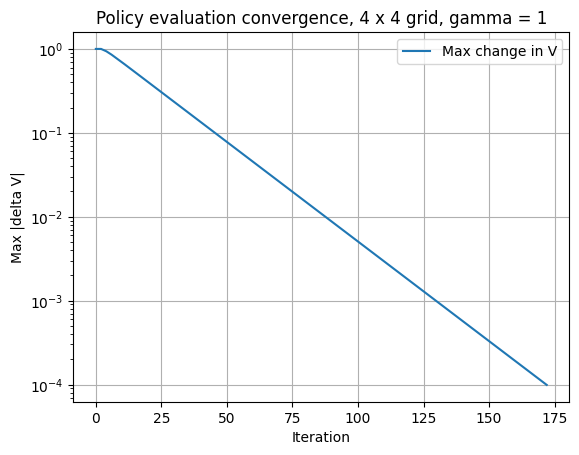

In [4]:
env = GridWorld(N=4, terminal_states={0, 15})
V, deltas = policy_eval(env)
print("Iterations to converge:", len(deltas))
env.render_values(V)

plt.figure()
plt.plot(deltas, label="Max change in V")
plt.title("Policy evaluation convergence, 4 x 4 grid, gamma = 1")
plt.xlabel("Iteration"); plt.ylabel("Max |delta V|")
plt.yscale("log"); plt.legend(); plt.grid(True); plt.show()

### Q1.2 Effect of gamma, theta and grid size

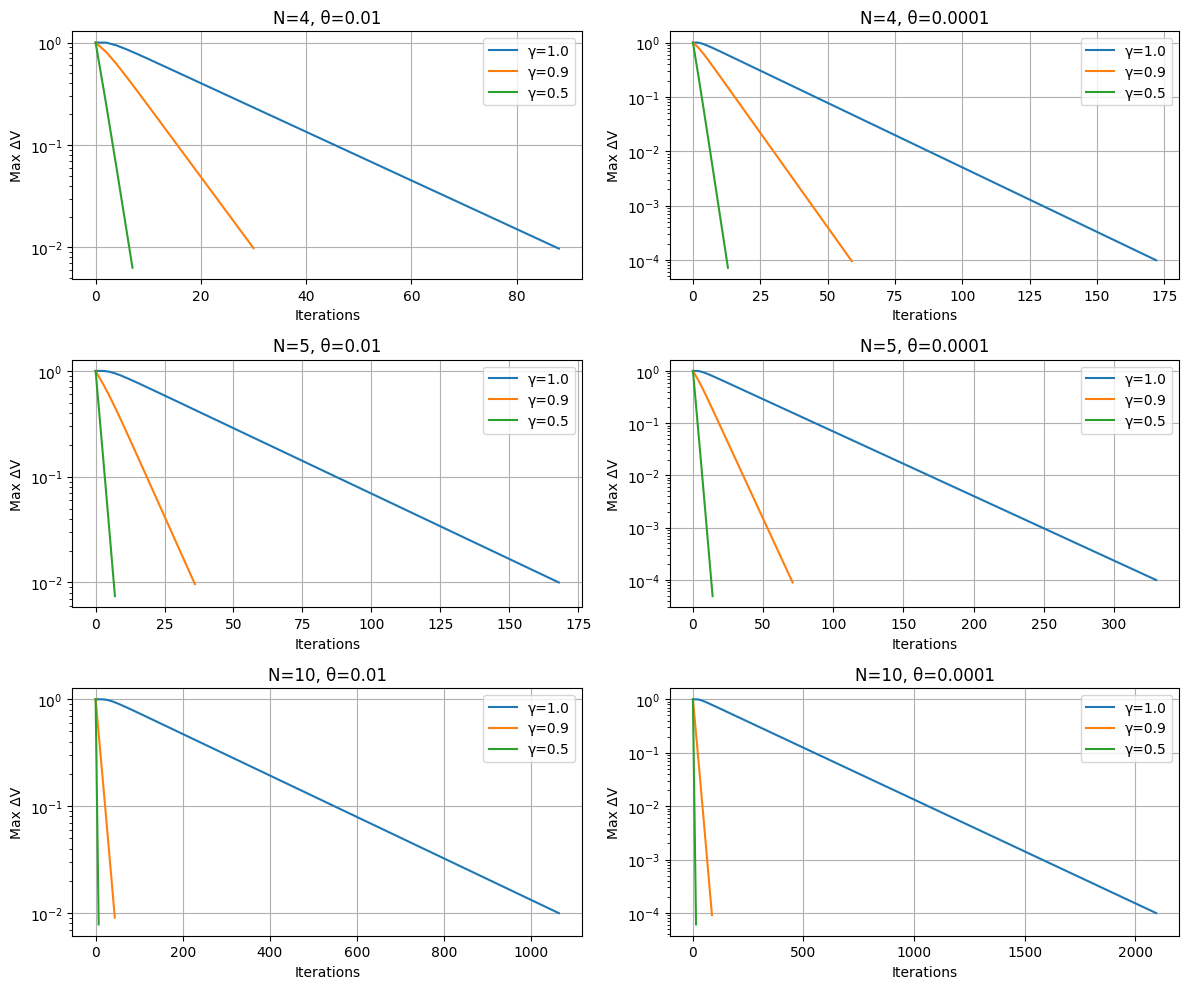

In [5]:
def run_parameter_sweep():
    gammas = [1.0, 0.9, 0.5]
    thetas = [1e-2, 1e-4]
    sizes  = [4, 5, 10]

    fig, axes = plt.subplots(len(sizes), len(thetas),
                             figsize=(12, 10))

    for i, N in enumerate(sizes):
        for j, theta in enumerate(thetas):
            ax = axes[i][j]

            for gamma in gammas:
                env = GridWorld(N=N, terminal_states={0, N*N - 1})
                _, deltas = policy_eval(env, gamma, theta)
                ax.plot(deltas, label=f"γ={gamma}")

            ax.set_title(f"N={N}, θ={theta}")
            ax.set_xlabel("Iterations")
            ax.set_ylabel("Max ΔV")
            ax.set_yscale('log')   
            ax.legend()     
            ax.grid(True)

    plt.tight_layout()
    plt.show()

run_parameter_sweep()

### Q1.3 Deterministic vs stochastic moves (0.8 intended, 0.1 to each side)

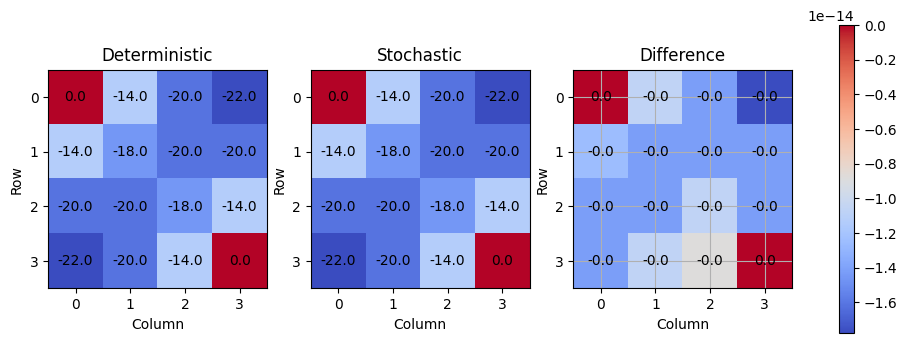

In [6]:
def compare_stochastic():
    env_d = GridWorld(4, {0, 15}, stochastic=False)
    env_s = GridWorld(4, {0, 15}, stochastic=True)

    Vd, _ = policy_eval(env_d)
    Vs, _ = policy_eval(env_s)

    fig, axes = plt.subplots(1, 3, figsize=(12, 4))
    ims = []
    
    for ax, V, title in zip(
        axes,
        [Vd, Vs, Vs - Vd],
        ["Deterministic", "Stochastic", "Difference"]
    ):
        
        im = ax.imshow(V.reshape(4, 4), cmap="coolwarm")
        ims.append(im)
        ax.set_title(title)
        ax.set_xlabel("Column")
        ax.set_ylabel("Row")

        # ADD VALUES ON GRID
        for i in range(4):
            for j in range(4):
                ax.text(j, i, f"{V[i*4+j]:.1f}",
                        ha="center", va="center", color="black")
    
    fig.colorbar(ims[-1], ax=axes.ravel().tolist())
    ax.grid(True)

    plt.show()

compare_stochastic()

## Part 2: Monte Carlo prediction

In [7]:
def mc_prediction(env, episodes=500, gamma=1.0, first_visit=True):
    V = np.zeros(env.n_states)
    returns = {s: [] for s in range(env.n_states)}
    history = []

    for _ in range(episodes):
        episode = env.generate_episode()

        G = 0
        visited = set()

        for t in reversed(range(len(episode))):
            s, a, r = episode[t]
            G = gamma * G + r

            if first_visit and s in visited:
                continue

            visited.add(s)
            returns[s].append(G)
            V[s] = np.mean(returns[s])

        history.append(V.copy())

    return V, np.array(history)


### Q2.1-2.2 First-visit vs every-visit on a 2 x 3 grid with an always-up policy

The top row (states 0, 1, 2) is terminal, with rewards -1, +1 and 0 for entering them.

First-visit converged at episode: 1
Every-visit converged at episode: 0


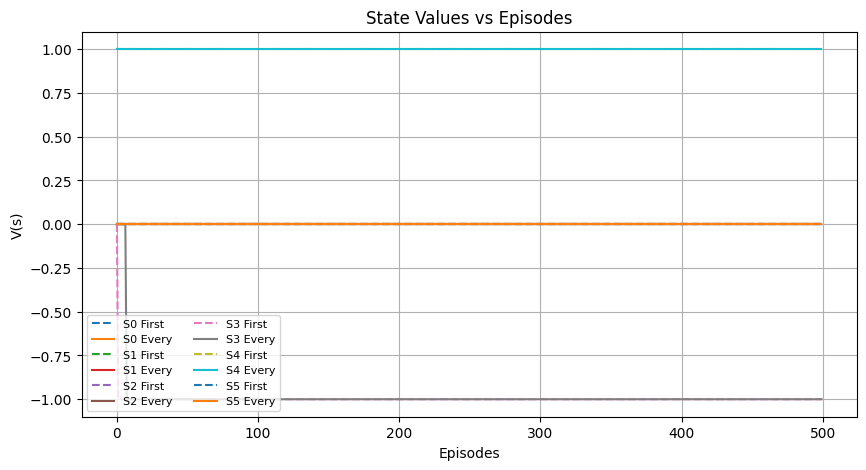

Final V (First-Visit): [ 0.  0.  0. -1.  1.  0.]
Final V (Every-Visit): [ 0.  0.  0. -1.  1.  0.]


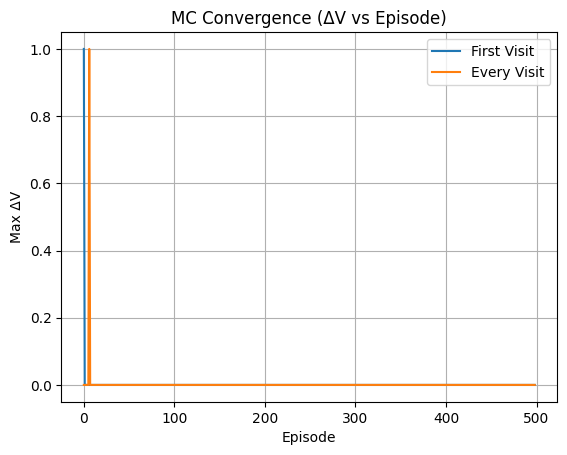

In [8]:
def custom_reward(s, a, ns):
    if ns == 0: return -1
    if ns == 1: return +1
    if ns == 2: return 0
    return 0

def mc_convergence():
    env = GridWorld(2, {0,1,2}, ncols=3, reward_fn=custom_reward)
    
    # deterministic UP policy
    policy = np.zeros((env.n_states, env.n_actions))
    policy[:, 0] = 1
    env.set_policy(policy)

    V1, h1 = mc_prediction(env, first_visit=True)

    env.set_policy(policy)
    V2, h2 = mc_prediction(env, first_visit=False)
    
    # Convergence detection
    for i in range(len(h1)-1):
        if np.max(np.abs(h1[i+1] - h1[i])) < 0.01:
            print("First-visit converged at episode:", i)
            break

    for i in range(len(h2)-1):
        if np.max(np.abs(h2[i+1] - h2[i])) < 0.01:
            print("Every-visit converged at episode:", i)
            break
            
    # Plot V(s) vs episodes for each state
    plt.figure(figsize=(10,5))

    for s in range(env.n_states):
        plt.plot(h1[:, s], linestyle='--', label=f"S{s} First")
        plt.plot(h2[:, s], linestyle='-', label=f"S{s} Every")

    plt.title("State Values vs Episodes")
    plt.xlabel("Episodes")
    plt.ylabel("V(s)")
    plt.grid(True)

    plt.legend(ncol=2, fontsize=8)  # cleaner legend
    plt.show()
    
    print("Final V (First-Visit):", V1)
    print("Final V (Every-Visit):", V2)

    plt.figure()
    plt.plot(np.max(np.abs(np.diff(h1, axis=0)), axis=1), label="First Visit")
    plt.plot(np.max(np.abs(np.diff(h2, axis=0)), axis=1), label="Every Visit")
    plt.title("MC Convergence (ΔV vs Episode)")
    plt.xlabel("Episode")
    plt.ylabel("Max ΔV")
    plt.grid(True)
    plt.legend()
    plt.show()

mc_convergence()

### Q2.3 MC estimates from the given episodes

In [9]:
def empirical_mc():
    episodes = [
        [("s1","a1",3),("s1","a2",2),("s2","a2",-4),("s1","a2",4),("s2","a1",-3)],
        [("s2","a1",-2),("s1","a2",3),("s2","a2",-3)],
        [("s1","a1",1),("s1","a2",4),("s1","a2",1),("s2","a1",-1)]
    ]

    returns = {}
    Q = {}

    for ep in episodes:
        G = 0
        for s,a,r in reversed(ep):
            G += r
            returns.setdefault(s, []).append(G)
            Q.setdefault((s,a), []).append(G)

    print("V(s):", {s: np.mean(v) for s,v in returns.items()})
    print("Q(s,a):", {k: np.mean(v) for k,v in Q.items()})

empirical_mc()

V(s): {'s2': np.float64(-2.4), 's1': np.float64(1.5714285714285714)}
Q(s,a): {('s2', 'a1'): np.float64(-2.0), ('s1', 'a2'): np.float64(0.8), ('s2', 'a2'): np.float64(-3.0), ('s1', 'a1'): np.float64(3.5)}


## Part 3: Monte Carlo control on a single trajectory

In [10]:
def mc_control_simple():
    traj = [
        ("A","a1",2), ("A","a2",-1),
        ("B","a2",3), ("A","a2",2),
        ("A","a1",-1), ("B","a1",-4)
    ]

    Q = {}
    G = 0

    for s, a, r in reversed(traj):
        G += r
        Q.setdefault((s, a), []).append(G)

    Q = {k: np.mean(v) for k, v in Q.items()}
    print("Q-values:", Q)

mc_control_simple()

Q-values: {('B', 'a1'): np.float64(-4.0), ('A', 'a1'): np.float64(-2.0), ('A', 'a2'): np.float64(-2.0), ('B', 'a2'): np.float64(0.0)}


## Part 4: Batch TD(0)

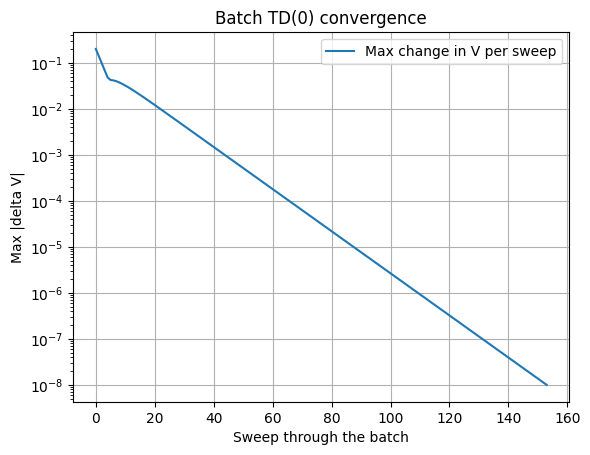

Batch TD(0) values: {'A': 0.6667, 'B': 0.6667, 'T': 0.0}
Batch Monte Carlo values: {'A': 0.0, 'B': 0.6667}


In [11]:
def batch_td():
    """Batch TD(0): sum the TD increments over the whole batch of episodes,
    then apply them once per sweep, until V stops changing.

    (My first version applied each increment immediately, which is ordinary
    online TD(0) replayed many times and settles at 0.701 instead of 2/3.)
    """
    episodes = [
        [("A", 0, "B"), ("B", 0, "T")],
        [("B", 1, "T")],
        [("B", 1, "T")]
    ]

    V = {"A": 0.0, "B": 0.0, "T": 0.0}
    alpha = 0.1
    gamma = 1.0

    deltas = []

    for _ in range(10000):
        increments = {s: 0.0 for s in V}
        for ep in episodes:
            for s, r, ns in ep:
                increments[s] += alpha * (r + gamma * V[ns] - V[s])
        for s in V:
            V[s] += increments[s]
        delta = max(abs(x) for x in increments.values())
        deltas.append(delta)
        if delta < 1e-8:
            break

    plt.figure()
    plt.plot(deltas, label="Max change in V per sweep")
    plt.title("Batch TD(0) convergence")
    plt.xlabel("Sweep through the batch")
    plt.ylabel("Max |delta V|")
    plt.yscale("log")
    plt.legend()
    plt.grid(True)
    plt.show()

    print("Batch TD(0) values:", {s: round(v, 4) for s, v in V.items()})

    # Batch Monte Carlo for comparison: V(s) = average return observed from s
    returns = {"A": [], "B": []}
    for ep in episodes:
        G = 0
        for s, r, ns in reversed(ep):
            G = r + gamma * G
            returns[s].append(G)
    print("Batch Monte Carlo values:", {s: round(float(np.mean(g)), 4) for s, g in returns.items()})

batch_td()

## Observations

**Policy evaluation (4 x 4, gamma = 1).** The equiprobable random policy converges in 173 sweeps to the classic values 0, -14, -18, -20 and -22 (Sutton and Barto, Figure 4.1): the expected number of steps a random walk takes to reach a terminal corner.

**Effect of gamma, theta and grid size.** Smaller gamma converges much faster, because errors shrink by at least a factor of gamma per sweep. With gamma = 1 convergence relies only on the terminal states, so it slows sharply as the grid grows: at theta = 1e-4 it takes about 173 sweeps for 4 x 4, 330 for 5 x 5 and 2,100 for 10 x 10, against about 15 sweeps with gamma = 0.5 at any size. A smaller theta adds sweeps roughly in proportion to log(1/theta), since the error falls geometrically.

**Deterministic vs stochastic moves.** The two value functions are identical (differences of order 1e-14, rounding error). Under the *equiprobable* policy, slipping to a perpendicular direction only reshuffles which of the four equally likely moves happens, so the distribution of next states is unchanged. Slip would matter for a non-uniform (for example greedy) policy.

**First-visit vs every-visit MC.** On the 2 x 3 grid with the always-up policy, every episode is one step long and deterministic. So both methods get the exact values (-1, +1, 0 for the bottom row) after the first visit to each state, and there is no difference between them.

**Batch TD(0) vs batch Monte Carlo.** On the A-B example, batch TD gives V(A) = V(B) = 2/3, while batch MC gives V(A) = 0 and V(B) = 2/3. MC uses only the single return actually seen from A (0). TD uses the fact that A always leads to B and bootstraps from V(B). That is the certainty-equivalence estimate, and it is usually better on future data.